# Project X | Completed Financial Analysis

**Reproducible analyst notebook · As of June 2032**

This notebook builds on the original GL-cleaning work, preserves its documented source-total exceptions, validates the $58 million monthly baseline, and answers the six leadership questions in the case brief. All dollar figures come from the provided workbook; projections and proposed controls are explicitly labeled as estimates or illustrative actions. Run all cells top to bottom with the Excel data pack in the same folder (or in `/mnt/data`).

## 1. Executive summary — calculated in Section 10

The approved department plan is **$58 million**, plus **$2 million of unallocated management reserve** for a **$60 million funding ceiling**. Actual spending is final through **June 2032**; the **June 2032 forecast vintage** applies to July 2032–December 2033. The December 2031 forecast vintage covers months now replaced by actuals and must not be added to the current projection.

**Reading guide.** Sections 2–4 preserve the original data-cleaning and reconciliation work. Sections 6–10 calculate spend, scenarios, department risk, and indicative corrective actions. The last section provides the findings, decisions and caveats for the leadership presentation. The 2030/2031 source subtotals and grand-total cell remain inconsistent with the clean detail; the notebook discloses rather than overwrites those exceptions.

## 2. Load source data and establish the audit trail

**Why.** The export is not a ready-to-analyze table: its display headings sit above the actual column names, it contains subtotal/total rows, and some amounts are stored as strings. We preserve the imported source **before** changing any values. `_source_row_id` is an internal, stable identifier that allows us to remove duplicates proven identical in the original export without relying solely on `Doc ID`.

**Reproducibility.** Run **Kernel → Restart & Run All**. The notebook rebuilds `GLE_df` from the original workbook every time. Do not execute isolated mutating cells repeatedly on an already cleaned DataFrame.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

DATA_FILE = Path("ProjectX_Student_Data_Pack.xlsx")
if not DATA_FILE.exists():
    DATA_FILE = Path("/mnt/data/ProjectX_Student_Data_Pack.xlsx")
assert DATA_FILE.exists(), "Set DATA_FILE to the location of ProjectX_Student_Data_Pack.xlsx"

GL_FIELDS = [
    "Doc ID", "Posting Period", "Rec Type", "Version", "Cost Center",
    "Dept", "Txn Class", "GL Acct", "Account Description",
    "Amount (USD)", "Memo"
]

GLE_raw = pd.read_excel(DATA_FILE, sheet_name="GL_Extract", header=3)
GLE_df = GLE_raw.copy(deep=True)
GLE_df["_source_row_id"] = GLE_df.index
BLP_df = pd.read_excel(DATA_FILE, sheet_name="Baseline_Plan", header=3)
department = pd.read_excel(DATA_FILE, sheet_name="Dept_Directory")

print("Raw GL shape:", GLE_raw.shape)
print("Baseline Plan shape:", BLP_df.shape)
print("Department directory shape:", department.shape)
print("Original GL fields present:", set(GL_FIELDS).issubset(GLE_raw.columns))
assert set(GL_FIELDS).issubset(GLE_raw.columns)

Raw GL shape: (5271, 11)
Baseline Plan shape: (20, 51)
Department directory shape: (10, 3)
Original GL fields present: True


### 2.1 Initial quality assessment

**Approach.** Inspect field types, null counts, unique values and repeated identifiers *before* altering transaction content. A repeated document ID is a lead for investigation, not proof of an erroneous line: in many ledgers, one document may legitimately have multiple lines.

In [2]:
display(pd.DataFrame({
    "dtype": GLE_raw.dtypes.astype(str),
    "missing": GLE_raw.isna().sum(),
    "distinct_nonmissing": GLE_raw.nunique(dropna=True)
}))
for col in ["Rec Type", "Version", "Dept", "Txn Class"]:
    print(f"\n{col}:\n{GLE_raw[col].value_counts(dropna=False).head(20)}")

,dtype,missing,distinct_nonmissing
Doc ID,object,3,5250
Posting Period,object,3,240
Rec Type,object,13,10
Version,object,3,3
Cost Center,object,3,10
Dept,object,17,60
Txn Class,object,3,12
GL Acct,float64,3,10
Account Description,object,0,39
Amount (USD),object,0,5242



Rec Type:
Rec Type
Actual      1870
Forecast    1047
A            389
Actuals      389
Act          363
ACT          354
FCST         219
FC           213
Fcst         211
F            203
NaN           13
Name: count, dtype: int64

Version:
Version
Posted         3372
Fcst Jun-32    1422
Fcst Dec-31     474
NaN               3
Name: count, dtype: int64

Dept:
Dept
2         272
3         258
6         246
5         241
9         239
1         235
7         228
4         214
10        208
8         179
Dept 2     96
04         95
Dept 1     94
Dept 3     91
03         89
Dept 7     88
Dept 4     87
02         86
09         85
Dept 5     79
Name: count, dtype: int64

Txn Class:
Txn Class
Non-Labor    1470
Labor        1118
LABOR         345
NL            300
Non-labor     299
NON-LABOR     299
N/L           298
NonLabor      289
Non Labor     278
Lbr           208
L             189
labor         175
NaN             3
Name: count, dtype: int64


## 3. General Ledger cleaning

The guiding principle is **preserve the original records and document each rule**. We treat identifiers as identifiers, use the accounting policy to resolve classification labels, and retain adjustments/reversals. Changes to labeling should not change a transaction's financial amount.

### 3.1 Separate source summary rows; standardize `Posting Period`

**Problem.** Posting periods appear as `01/2030`, `2030-01`, month names, and sometimes month-end dates. They describe **months**, not individual days. In addition, the source contains two FY actual subtotal rows and a grand-total row that are *not* individual transactions.

**Solution.** Save these summary records separately and exclude them from transaction aggregation. Convert remaining dates with `pd.to_datetime(..., format="mixed", errors="coerce")`, followed by `.dt.to_period("M")`. `errors="coerce"` is acceptable here only because failed conversions are tested immediately; a `NaT` would be a flagged issue, not an instruction to delete a record.

**Evidence to verify:** 48 monthly periods from `2030-01` through `2033-12`, and no missing periods after the source summary records are excluded.

In [3]:
desc = GLE_df["Account Description"].astype("string").str.strip()
subtotal_mask = desc.str.lower().str.startswith("subtotal", na=False)
grand_mask = desc.eq("TOTAL - ALL ROWS").fillna(False)

GLE_subtotals = GLE_df.loc[subtotal_mask].copy()
GLE_grand_total_row = GLE_df.loc[grand_mask].copy()
GLE_df = GLE_df.loc[~(subtotal_mask | grand_mask)].copy()

GLE_df["Posting Period"] = pd.to_datetime(
    GLE_df["Posting Period"], format="mixed", errors="coerce"
).dt.to_period("M")

print("Subtotal rows preserved:", len(GLE_subtotals))
print("Grand-total rows preserved:", len(GLE_grand_total_row))
print("Transaction candidates:", len(GLE_df))
print("Missing posting periods:", GLE_df["Posting Period"].isna().sum())
print("Distinct periods:", GLE_df["Posting Period"].nunique())
print("Date range:", GLE_df["Posting Period"].min(), "to", GLE_df["Posting Period"].max())
assert len(GLE_subtotals) == 2
assert len(GLE_grand_total_row) == 1
assert GLE_df["Posting Period"].notna().all()
assert GLE_df["Posting Period"].nunique() == 48

Subtotal rows preserved: 2
Grand-total rows preserved: 1
Transaction candidates: 5268
Missing posting periods: 0
Distinct periods: 48
Date range: 2030-01 to 2033-12


**Finding and decision.** The two subtotal records relate to FY2030 and FY2031 actuals. They are retained in `GLE_subtotals` as **reported control totals**, not treated as transaction amounts. The grand-total record is held in `GLE_grand_total_row` for a separate comparison. Excluding these rows prevents double-counting.

### 3.2 Standardize `Rec Type` and resolve missing labels

**Problem.** Actual and forecast records appear under multiple abbreviations (`Actual`, `Act`, `ACT`, `A`, `Forecast`, `FCST`, `FC`, `F`, etc.), and 10 transaction records have missing labels after summary-row exclusion.

**Solution.** Normalize leading/trailing spaces and case; classify known labels beginning with `a` as `Actual` and `f` as `Forecast`. For missing entries **only**, use the verified version convention: `Posted` → `Actual`, `Fcst ...` → `Forecast`. Any unknown or contradictory value should halt validation rather than be assigned by guesswork.

**Finding.** The 10 missing labels were resolved using version evidence (7 Posted, 3 Fcst Jun-32). Preserve the original raw values in `GLE_raw`.

In [4]:
rec = GLE_df["Rec Type"].astype("string").str.strip().str.lower()
actual_mask = rec.str.startswith("a", na=False)
forecast_mask = rec.str.startswith("f", na=False)
unknown_rec = rec.notna() & ~(actual_mask | forecast_mask)
assert not unknown_rec.any(), "Unexpected Rec Type labels require investigation"

GLE_df.loc[actual_mask, "Rec Type"] = "Actual"
GLE_df.loc[forecast_mask, "Rec Type"] = "Forecast"
missing_rec = GLE_df["Rec Type"].isna()
GLE_df.loc[missing_rec & GLE_df["Version"].eq("Posted"), "Rec Type"] = "Actual"
GLE_df.loc[missing_rec & GLE_df["Version"].astype("string").str.startswith("Fcst", na=False), "Rec Type"] = "Forecast"

assert GLE_df["Rec Type"].notna().all(), "Unresolved record types"
assert set(GLE_df["Rec Type"].unique()) == {"Actual", "Forecast"}
print(GLE_df["Rec Type"].value_counts(dropna=False))
display(pd.crosstab(GLE_df["Rec Type"], GLE_df["Version"], dropna=False))

Rec Type
Actual      3372
Forecast    1896
Name: count, dtype: int64


Version,Fcst Dec-31,Fcst Jun-32,Posted
Rec Type,,,
Actual,0,0,3372
Forecast,474,1422,0


### 3.3 Clean `Dept` and verify `Cost Center`

**Problem.** Departments are recorded as integers, zero-padded strings and prefixed text (`6`, `06`, `Dept 6`, `D6`). Some department values are absent.

**Solution.** Extract the digits and store the result as nullable integer `Int64`, then independently parse `Cost Center` values such as `PX-D06`. Compare the two fields wherever both exist; impute only missing departments when the cost-center identifier is valid. **Do not overwrite conflicts automatically.**

**Finding.** The earlier notebook identified 14 transaction rows with missing departments and no conflicts among records where both identifiers were populated; those 14 can be recovered using cost centers. The full-column equality check below tests the result.

In [5]:
dept_source = GLE_df["Dept"].astype("string").str.strip()
dept_digits = dept_source.str.extract(r"^(?:Dept\.?\s*|D)?0*(\d{1,2})$", flags=__import__('re').IGNORECASE, expand=False)
# Retain evidence of unexpected nonblank source strings rather than silently discarding them.
invalid_dept_labels = dept_source.notna() & dept_digits.isna()
assert not invalid_dept_labels.any(), "Unrecognized Dept labels"
GLE_df["Dept"] = pd.to_numeric(dept_digits, errors="coerce").astype("Int64")

cost_center_dept = pd.to_numeric(
    GLE_df["Cost Center"].astype("string")
    .str.extract(r"^PX-D(\d{1,2})$", expand=False),
    errors="coerce"
).astype("Int64")

mismatch = (
    GLE_df["Dept"].notna() & cost_center_dept.notna()
    & GLE_df["Dept"].ne(cost_center_dept)
).fillna(False)
missing_before = int(GLE_df["Dept"].isna().sum())
print("Missing departments before fill:", missing_before)
print("Conflicts with cost centers:", int(mismatch.sum()))
assert not mismatch.any(), "Investigate Dept / Cost Center inconsistencies"
GLE_df["Dept"] = GLE_df["Dept"].fillna(cost_center_dept)
assert GLE_df["Dept"].notna().all()
assert GLE_df["Dept"].isin(range(1, 11)).all()
assert GLE_df["Dept"].equals(cost_center_dept)
print("Missing after fill:", GLE_df["Dept"].isna().sum())
print("Departments:", GLE_df["Dept"].nunique())

Missing departments before fill: 14
Conflicts with cost centers: 0
Missing after fill: 0
Departments: 10


### 3.4 Resolve `Txn Class` under the accounting policy

**Problem.** `Labor`, `LABOR`, `L`, `Lbr`, `Non-Labor`, `NL`, etc. are inconsistent; more importantly, **25 contract-labor records** were labeled as Non-Labor even though the chart-of-accounts policy identifies them as Labor.

**Solution.** Use the validated **GL account code** as the classification authority: accounts `6000, 6100, 6200, 6300` → Labor; `7000`–`7500` in 100-point increments → Non-Labor. This is better than checking whether a label contains the letter `n`, which can incorrectly classify unexpected strings. Retain a copy of the original labels and a separate audit table for contradictions.

**Finding.** Before deduplication, 25 GL-6300 records conflict with the policy; the override corrects them but does not alter amounts. Counts below are pre-deduplication at this stage, so they will change slightly after Section 3.8.

In [6]:
labor_codes = {6000, 6100, 6200, 6300}
nonlabor_codes = {7000, 7100, 7200, 7300, 7400, 7500}
acct_num = pd.to_numeric(GLE_df["GL Acct"], errors="coerce")
assert acct_num.isin(labor_codes | nonlabor_codes).all(), "Unexpected GL account: do not classify blindly"

original_txn_class = GLE_df["Txn Class"].copy()
raw_txn_label = original_txn_class.astype("string").str.lower().str.strip()
orig_nonlabor = raw_txn_label.str.contains("n", na=False)
orig_labor = raw_txn_label.notna() & ~orig_nonlabor

labor_mask = acct_num.isin(labor_codes)
nonlabor_mask = acct_num.isin(nonlabor_codes)
class_conflict = (labor_mask & orig_nonlabor) | (nonlabor_mask & orig_labor)
GLE_txn_class_errors = GLE_df.loc[class_conflict].copy()
GLE_txn_class_errors["Original Txn Class"] = original_txn_class.loc[class_conflict]

GLE_df.loc[labor_mask, "Txn Class"] = "Labor"
GLE_df.loc[nonlabor_mask, "Txn Class"] = "Non-Labor"
print("Classification inconsistencies preserved:", len(GLE_txn_class_errors))
print(GLE_df["Txn Class"].value_counts(dropna=False))
assert GLE_df["Txn Class"].notna().all()

Classification inconsistencies preserved: 25
Txn Class
Non-Labor    3208
Labor        2060
Name: count, dtype: int64


### 3.5 Validate `GL Acct` (identifier, not measured quantity)

**Problem.** Source account codes were represented as floating-point values (e.g. `6300.0`). Their numeric magnitude is not an amount to be summed or averaged.

**Solution.** Convert to nullable integer `Int64` and assert membership in the approved 10-code list. Since the code set already passed initial checks, this is primarily **type normalization and validation**.

In [7]:
GLE_df["GL Acct"] = pd.to_numeric(GLE_df["GL Acct"], errors="coerce").astype("Int64")
assert GLE_df["GL Acct"].notna().all()
assert GLE_df["GL Acct"].isin(labor_codes | nonlabor_codes).all()
print("Unique GL accounts:", GLE_df["GL Acct"].nunique())
display(pd.crosstab(GLE_df["GL Acct"], GLE_df["Txn Class"]))

Unique GL accounts: 10


Txn Class,Labor,Non-Labor
GL Acct,,
6000,543,0
6100,542,0
6200,489,0
6300,486,0
7000,0,554
7100,0,385
7200,0,320
7300,0,608
7400,0,711


### 3.6 Standardize `Account Description` from the account code

**Problem.** There are multiple descriptions for one code due to capitalization, abbreviations and spelling (`Contract Labor` / `Contract Labour` / `Contract Lbr`). Text differences should not create artificial expense categories.

**Solution.** Map each approved GL account code to its canonical description. Keep the source description in `Account Description Original`. This is a **label normalization**, not a financial adjustment. Account names should ultimately be checked against the workbook's official `Data_Dictionary`.

In [8]:
account_map = {
    6000: "Salaries & Wages",
    6100: "Benefits & Payroll Tax",
    6200: "Overtime",
    6300: "Contract Labor",
    7000: "Materials & Supplies",
    7100: "Equipment & Hardware",
    7200: "Software & Licences",
    7300: "Travel & Expenses",
    7400: "Professional Services",
    7500: "Facilities & Other",
}
GLE_df["Account Description Original"] = GLE_df["Account Description"].copy()
GLE_df["Account Description"] = GLE_df["GL Acct"].map(account_map)
assert GLE_df["Account Description"].notna().all()
assert GLE_df.groupby("GL Acct")["Account Description"].nunique().eq(1).all()
print("Distinct descriptions after mapping:", GLE_df["Account Description"].nunique())

Distinct descriptions after mapping: 10


### 3.7 Convert `Amount (USD)` without losing signs

**Problem.** The column mixes strings and Python numbers; some strings contain `$` and thousands separators. Direct `pd.to_numeric()` on the uncleaned column would coerce valid dollar values to missing data.

**Solution.** Preserve `Amount Original`; remove only `$`, commas and surrounding whitespace; parse to numeric. Flag any nonmissing original value that fails to convert. **Do not take absolute values**: negatives can be legitimate reversals.

**Finding.** The prior notebook found 10 negative reversal entries. Their `-R` document IDs and memo references warrant matching against originals; they should not be deleted as outliers.

In [9]:
GLE_df["Amount Original"] = GLE_df["Amount (USD)"].copy()
amount_text = (
    GLE_df["Amount (USD)"].astype("string").str.strip()
    .str.replace(r"[$,]", "", regex=True)
)
# Do not silently interpret accounting parentheses unless the raw data shows this convention.
parenthesis_mask = amount_text.str.contains(r"[()]", regex=True, na=False)
assert not parenthesis_mask.any(), "Accounting parentheses need explicit signed conversion"
GLE_df["Amount (USD)"] = pd.to_numeric(amount_text, errors="coerce")
failed_amounts = GLE_df["Amount Original"].notna() & GLE_df["Amount (USD)"].isna()
assert not failed_amounts.any(), "Amount conversion lost nonmissing values"
assert GLE_df["Amount (USD)"].notna().all()
print("Converted dtype:", GLE_df["Amount (USD)"].dtype)
print("Failed conversions:", int(failed_amounts.sum()))
print("Negative entries:", int(GLE_df["Amount (USD)"].lt(0).sum()))
display(GLE_df["Amount (USD)"].describe().to_frame("Amount (USD)"))

Converted dtype: Float64
Failed conversions: 0
Negative entries: 10


,Amount (USD)
count,5268.0
mean,14607.804074
std,32770.71904
min,-165623.33
25%,1841.31
50%,5989.76
75%,17032.14
max,1522972.6


#### 3.7.1 Verify reversal pairs (control, not a deletion rule)

Use the `Memo` text to extract referenced original IDs; compare every negative record with its referenced positive entry. The expected validation is that the signed amounts cancel, with no missing references. A matching pair is legitimate **net zero** for the combination, but both journal entries remain in the transactional audit trail.

In [10]:
reversals = GLE_df.loc[GLE_df["Amount (USD)"].lt(0), [
    "Doc ID", "Memo", "Amount (USD)"
]].copy()
reversals["Original Doc ID"] = reversals["Memo"].astype("string").str.extract(
    r"Reversal of (GL-\d+-X)", expand=False
)
# Duplicates are removed in 3.8; use a grouped lookup here so repeated source IDs
# cannot invalidate the index. The unique-value assertion prevents ambiguity.
assert GLE_df.groupby("Doc ID")["Amount (USD)"].nunique().le(1).all()
original_lookup = GLE_df.groupby("Doc ID")["Amount (USD)"].first()
reversals["Original Amount"] = reversals["Original Doc ID"].map(original_lookup)
reversals["Pair Net"] = reversals["Amount (USD)"] + reversals["Original Amount"]
display(reversals)
print("Unmatched reversal originals:", reversals["Original Amount"].isna().sum())
print("Non-offsetting pairs:", (~reversals["Pair Net"].abs().le(0.01)).sum())
assert reversals["Original Amount"].notna().all()
assert reversals["Pair Net"].abs().le(0.01).all()

,Doc ID,Memo,Amount (USD),Original Doc ID,Original Amount,Pair Net
1059,GL-101037-R,Reversal of GL-101037-X,-10003.66,GL-101037-X,10003.66,0.0
1417,GL-101382-R,Reversal of GL-101382-X,-22648.73,GL-101382-X,22648.73,0.0
1441,GL-101411-R,Reversal of GL-101411-X,-7430.93,GL-101411-X,7430.93,0.0
1632,GL-101634-R,Reversal of GL-101634-X,-16759.16,GL-101634-X,16759.16,0.0
1659,GL-101604-R,Reversal of GL-101604-X,-9059.32,GL-101604-X,9059.32,0.0
1875,GL-101794-R,Reversal of GL-101794-X,-93580.08,GL-101794-X,93580.08,0.0
1929,GL-101907-R,Reversal of GL-101907-X,-165623.33,GL-101907-X,165623.33,0.0
2398,GL-102373-R,Reversal of GL-102373-X,-32089.46,GL-102373-X,32089.46,0.0
2673,GL-102612-R,Reversal of GL-102612-X,-11083.62,GL-102612-X,11083.62,0.0
2937,GL-102792-R,Reversal of GL-102792-X,-12967.5,GL-102792-X,12967.5,0.0


Unmatched reversal originals: 0
Non-offsetting pairs: 0


### 3.8 Identify and remove **exact source-row duplicates**

**Problem.** Eighteen entries appear a second time as identical copies across all 11 original GL fields. This is evidence of duplicated export records, unlike a repeated amount or a multi-line accounting document.

**Solution.** Detect duplication in `GLE_raw` using all original GL fields; preserve the extra copies and their amounts. Remove the corresponding rows from the working set using the retained `_source_row_id`, which is safer than treating every duplicate `Doc ID` as invalid. Dropping a copy only once prevents double-counting.

**Finding.** Eighteen extra rows account for **$159,832.69** of duplicated source transaction value. This explains part—but not all—of the difference from printed totals.

In [11]:
raw_transactions = GLE_raw.loc[GLE_raw["Doc ID"].notna()].copy()
all_duplicate_members = raw_transactions.duplicated(subset=GL_FIELDS, keep=False)
extra_duplicate_mask = raw_transactions.duplicated(subset=GL_FIELDS, keep="first")
GLE_duplicates = raw_transactions.loc[all_duplicate_members].copy()
GLE_duplicate_errors = raw_transactions.loc[extra_duplicate_mask].copy()
extra_raw_row_ids = set(GLE_duplicate_errors.index)

# Convert only for quantifying the excluded duplicate amount.
def parse_currency(s):
    return pd.to_numeric(s.astype("string").str.strip().str.replace(r"[$,]", "", regex=True), errors="coerce")

duplicate_amount = parse_currency(GLE_duplicate_errors["Amount (USD)"].copy()).sum()
print("Extra duplicate records:", len(GLE_duplicate_errors))
print(f"Excluded duplicate amount: ${duplicate_amount:,.2f}")

n_before = len(GLE_df)
GLE_df = GLE_df.loc[~GLE_df["_source_row_id"].isin(extra_raw_row_ids)].copy()
print("Rows before / after:", n_before, "/", len(GLE_df))
assert n_before - len(GLE_df) == len(GLE_duplicate_errors)
assert len(GLE_df) == 5250
# Original transaction IDs happen to be unique after these 18 exact copies are removed.
print("Repeated document IDs remaining:", int(GLE_df["Doc ID"].duplicated().sum()))
GLE_df = GLE_df.reset_index(drop=True)

Extra duplicate records: 18
Excluded duplicate amount: $159,832.69
Rows before / after: 5268 / 5250
Repeated document IDs remaining: 0


### 3.9 Final transaction-level validation

This is an automated gate between cleaning and analysis. It checks the data schema, period coverage, type/version consistency, department–cost-center agreement, expense classifications, numeric amounts and source-row duplication logic. If any assertion fails after a source refresh, investigate rather than modifying figures to satisfy an expectation.

In [12]:
assert len(GLE_df) == 5250
assert GLE_df["Posting Period"].notna().all()
assert GLE_df["Posting Period"].nunique() == 48
assert GLE_df["Rec Type"].isin(["Actual", "Forecast"]).all()
assert ((GLE_df["Rec Type"].eq("Actual") & GLE_df["Version"].eq("Posted")) |
        (GLE_df["Rec Type"].eq("Forecast") & GLE_df["Version"].astype("string").str.startswith("Fcst", na=False))).all()
assert GLE_df["Dept"].notna().all()
assert GLE_df["GL Acct"].notna().all()
assert GLE_df["Txn Class"].notna().all()
assert GLE_df["Account Description"].notna().all()
assert GLE_df["Amount (USD)"].notna().all()
assert GLE_df["_source_row_id"].is_unique

print("All post-cleaning validation checks passed.")
print("Transactions:", len(GLE_df))
print("Cleaned total across all versions: ${:,.2f}".format(GLE_df["Amount (USD)"].sum()))

All post-cleaning validation checks passed.
Transactions: 5250
Cleaned total across all versions: $76,794,079.17


## 4. Financial reconciliation

**Important distinction:** (1) a *raw-to-clean bridge* explains every change our pipeline made; (2) a *source-total reconciliation* checks whether the figures printed in the export are consistent with transactions. A correct cleaning bridge does **not** imply that the source's printed subtotals are reliable.

### 4.1 Raw-to-clean transaction bridge

Start from the sum of all raw records with a document ID. This excludes the two subtotals and one grand-total record by **record type**, not by arbitrary dollar thresholds. Subtract only the 18 proven extra copies. Renaming categories, converting data types, filling department IDs and retaining reversals should have **zero net amount effect**.

In [13]:
raw_transaction_amounts = parse_currency(raw_transactions["Amount (USD)"].copy())
assert raw_transaction_amounts.notna().all()
raw_txn_total = raw_transaction_amounts.sum()
clean_txn_total = GLE_df["Amount (USD)"].sum()
bridge = pd.DataFrame({
    "Step": ["Raw detail rows with Doc ID", "Exclude extra exact copies", "Cleaned transaction total"],
    "Records": [len(raw_transactions), -len(GLE_duplicate_errors), len(GLE_df)],
    "Amount (USD)": [raw_txn_total, -duplicate_amount, clean_txn_total]
})
display(bridge)
print("Unexplained raw-to-clean difference:", round(float(raw_txn_total - duplicate_amount - clean_txn_total), 2))
assert np.isclose(float(raw_txn_total - duplicate_amount), float(clean_txn_total), atol=0.01)

,Step,Records,Amount (USD)
0,Raw detail rows with Doc ID,5268,76953911.86
1,Exclude extra exact copies,-18,-159832.69
2,Cleaned transaction total,5250,76794079.17


Unexplained raw-to-clean difference: -0.0


### 4.2 Compare actuals with the FY2030 and FY2031 reported subtotals

The source has reported FY2030 and FY2031 **actuals** subtotal records. Recalculate full-year actuals from the deduplicated transaction set; compare like with like. A nonzero difference is a **source-total exception**, not permission to delete unmatched transactions.

**Known findings:** FY2030 is **+$438,014.52** higher than the reported subtotal; FY2031 is **+$1,370,675.34** higher. These remain unresolved pending source control logic or corrections supported by an audit trail.

In [14]:
actuals = GLE_df.loc[GLE_df["Rec Type"].eq("Actual")].copy()
actuals_by_year = actuals.groupby(actuals["Posting Period"].dt.year)["Amount (USD)"].sum()
reported_subtotals = GLE_subtotals.copy()
reported_subtotals["Year"] = reported_subtotals["Account Description"].str.extract(r"FY(\d{4})", expand=False).astype(int)
reported_subtotals["Reported"] = parse_currency(reported_subtotals["Amount (USD)"].copy())
reconciliation = pd.DataFrame({
    "Calculated": actuals_by_year,
    "Reported": reported_subtotals.set_index("Year")["Reported"]
}).dropna(subset=["Reported"])
reconciliation["Difference"] = reconciliation["Calculated"] - reconciliation["Reported"]
display(reconciliation)
print("Annual subtotal comparisons within $0.01:", reconciliation["Difference"].abs().le(0.01).to_dict())

,Calculated,Reported,Difference
2030,9139104.77,8701090.25,438014.52
2031,23199630.96,21828955.62,1370675.34


Annual subtotal comparisons within $0.01: {2030: False, 2031: False}


### 4.3 Compare against the original printed grand total

This comparison evaluates the source's reported total, **not** a project-to-completion projection. The cleaned GL sum combines actual records and two different forecast versions, so it should not be reported as spent or forecast at completion.

**Known finding:** $76,794,079.17 of cleaned transactions versus a printed grand total of $74,174,789.01, a **+$2,619,290.16** unresolved difference.

In [15]:
grand_total = parse_currency(GLE_grand_total_row["Amount (USD)"].copy()).iloc[0]
grand_difference = clean_txn_total - grand_total
print(f"Printed grand total: ${grand_total:,.2f}")
print(f"Cleaned transaction total (all versions): ${clean_txn_total:,.2f}")
print(f"Unresolved difference: ${grand_difference:,.2f}")

Printed grand total: $74,174,789.01
Cleaned transaction total (all versions): $76,794,079.17
Unresolved difference: $2,619,290.16


### 4.4 Separate actuals and forecast vintages

A key risk is double-counting forecast versions. The 2031 forecast and the June 2032 forecast are **alternative views**, not necessarily independent future spending to sum together. Inspect each forecast's time coverage and choose the correct period/version combination under the workbook's data dictionary.

**Reporting cutoff:** Project spent-to-date is the sum of `Actual / Posted` transactions through `2032-06`, **not** the all-version cleaned total. Historical actuals and future forecast should not overlap in a completion estimate.

In [16]:
version_summary = GLE_df.groupby(["Rec Type", "Version"], dropna=False)["Amount (USD)"].agg(["count", "sum"])
display(version_summary)
forecasts = GLE_df.loc[GLE_df["Rec Type"].eq("Forecast")]
forecast_periods = forecasts.groupby("Version")["Posting Period"].agg(["min", "max", "nunique"])
display(forecast_periods)
print("Forecast months by version (nonzero counts only):")
display(pd.crosstab(forecasts["Posting Period"], forecasts["Version"]))

AS_OF = pd.Period("2032-06", freq="M")
actuals_to_date = GLE_df.loc[
    GLE_df["Rec Type"].eq("Actual") & GLE_df["Posting Period"].le(AS_OF), "Amount (USD)"
].sum()
future_forecasts = GLE_df.loc[
    GLE_df["Rec Type"].eq("Forecast") & GLE_df["Posting Period"].gt(AS_OF)
]
print(f"Actuals through {AS_OF}: ${actuals_to_date:,.2f}")
print("Future forecast records by vintage:")
display(future_forecasts.groupby("Version")["Amount (USD)"].agg(["count", "sum"]))

count          sum
Rec Type Version                        
Actual   Posted        3354  45958579.78
Forecast Fcst Dec-31    474  11004831.13
         Fcst Jun-32   1422  19830668.26

,min,max,nunique
Version,,,
Fcst Dec-31,2032-01,2032-06,6
Fcst Jun-32,2032-07,2033-12,18


Forecast months by version (nonzero counts only):


Version,Fcst Dec-31,Fcst Jun-32
Posting Period,,
2032-01,79,0
2032-02,79,0
2032-03,79,0
2032-04,79,0
2032-05,79,0
2032-06,79,0
2032-07,0,79
2032-08,0,79
2032-09,0,79


Actuals through 2032-06: $45,958,579.78
Future forecast records by vintage:


,count,sum
Version,,
Fcst Jun-32,1422,19830668.26


### 4.5 Reconciliation conclusion and exceptions log

**What is resolved:** transaction-level cleaning is traceable; the only value-changing removal is $159,832.69 of exact duplicate copies. The 10 reversal pairs net to zero when combined with their originals. Dates, classifications, descriptions and department imputations do not change amounts.

**What is unresolved:** the two printed annual actual subtotals and the printed grand total disagree with recalculated transaction totals. Treat these as **open exceptions**, not financial adjustments. Possible explanations (unverified) include the source totals being generated with different inclusion rules, additional source defects, or a reporting logic mismatch. None of these hypotheses justifies removing transactions without supporting evidence.

**Recommended resolution:** ask for the report's subtotal/total specifications, reconcile by document population and source period/version, and preserve a table of any records excluded by a verified policy. If explanations are unavailable, report the difference explicitly and use transaction-derived amounts with a stated caveat.

## 5. Scope and methods for the remaining case

The reporting cut-off is **2032-06**. We use only `Posted` actual transactions for historic expenditure. The **`Fcst Jun-32`** submission covers the 18 future months; the six-month `Fcst Dec-31` vintage is historical and overlaps posted actuals. Combining those versions would double count alternative forecasts.

**Second projection.** The alternative is *plan-phased run-rate*: extrapolate the ratio of actual expenditure to the baseline across the most recent six posted months (Jan–Jun 2032) onto the remaining 18-month baseline. This respects the deliberately non-uniform monthly plan. We also show a flat dollars-per-month burn-rate sensitivity, **not** as the preferred scenario.

**Sign convention:** overspend / funding gap = positive; underspend / surplus = negative. Source-reconciliation exceptions remain as unresolved data-quality caveats.

## 6. Validate and reshape `Baseline_Plan`

**Purpose.** Verify that the originally approved plan is complete and self-consistent before using it as the benchmark. The 20 source rows represent 10 departments × 2 cost classes; month headers are Excel datetime labels. The plan is stored *wide*, with one column per month. A tidy long form is required to align with `GLE_df` on month, department, and class.

**Important correction:** imported month labels may be built-in `datetime.datetime`, not pandas `Timestamp`. Identify date-like columns by their type instead of slicing `[2:-1]`, which becomes unsafe if inspection columns were previously appended.

In [17]:
from datetime import date, datetime

BLP_raw = BLP_df.copy(deep=True)
monthly_cols = [c for c in BLP_raw.columns if isinstance(c, (pd.Timestamp, datetime, date))]
assert len(monthly_cols) == 48, f"Expected 48 month columns, found {len(monthly_cols)}"
assert BLP_raw.shape == (20, 51)
assert BLP_raw[monthly_cols].notna().all().all()
assert BLP_raw[["Dept", "Class", "Plan Total"]].notna().all().all()
assert set(BLP_raw["Dept"]) == set(range(1, 11))
assert set(BLP_raw["Class"]) == {"Labor", "Non-Labor"}
assert not BLP_raw.duplicated(["Dept", "Class"]).any()
assert (BLP_raw.groupby("Dept").size() == 2).all()

BLP_validation = BLP_raw[["Dept", "Class", "Plan Total"]].copy()
BLP_validation["Monthly Sum"] = BLP_raw[monthly_cols].sum(axis=1)
BLP_validation["Difference"] = BLP_validation["Monthly Sum"] - BLP_validation["Plan Total"]
assert np.isclose(BLP_validation["Difference"], 0, atol=0.01, rtol=0).all()
plan_total = float(BLP_validation["Monthly Sum"].sum())
assert np.isclose(plan_total, 58_000_000, atol=0.02, rtol=0)
print(f"Source grid: {BLP_raw.shape[0]} rows × {len(monthly_cols)} months")
print(f"Monthly baseline total: ${plan_total:,.2f} (one-cent source rounding)")
print("Max absolute row-total difference:", round(BLP_validation["Difference"].abs().max(), 4))
display(BLP_validation)

Source grid: 20 rows × 48 months
Monthly baseline total: $57,999,999.99 (one-cent source rounding)
Max absolute row-total difference: 0.0


,Dept,Class,Plan Total,Monthly Sum,Difference
0,1,Labor,3400000.00,3400000.00,-9.313226e-10
1,1,Non-Labor,599999.98,599999.98,-1.164153e-10
2,2,Labor,7200000.01,7200000.01,0.000000e+00
3,2,Non-Labor,1799999.97,1799999.97,2.328306e-10
4,3,Labor,1875000.01,1875000.01,-2.328306e-10
5,3,Non-Labor,5625000.01,5625000.01,9.313226e-10
6,4,Labor,6049999.96,6049999.96,1.862645e-09
7,4,Non-Labor,4950000.01,4950000.01,9.313226e-10
8,5,Labor,3900000.02,3900000.02,4.656613e-10
9,5,Non-Labor,2600000.00,2600000.00,0.000000e+00


### 6.1 Create an analysis-ready monthly baseline

`pd.melt()` transforms the 48 date columns into 960 observations (10 departments × 2 classes × 48 months). Convert dates to the same `period[M]` dtype as the ledger. Retain the original wide plan and its printed `Plan Total` without rewriting either. Every department/class/month key should be unique; the total must remain unchanged after reshaping.

In [18]:
BLP_long = BLP_raw.melt(
    id_vars=["Dept", "Class"], value_vars=monthly_cols,
    var_name="Posting Period", value_name="Baseline (USD)"
).rename(columns={"Class": "Txn Class"})
BLP_long["Posting Period"] = pd.to_datetime(BLP_long["Posting Period"]).dt.to_period("M")
BLP_long["Dept"] = BLP_long["Dept"].astype("Int64")
BLP_long["Baseline (USD)"] = pd.to_numeric(BLP_long["Baseline (USD)"])
keys = ["Dept", "Txn Class", "Posting Period"]
assert len(BLP_long) == 960
assert not BLP_long.duplicated(keys).any()
assert BLP_long["Posting Period"].nunique() == 48
assert np.isclose(BLP_long["Baseline (USD)"].sum(), plan_total, atol=0.01)
display(BLP_long.head())
print("Baseline by class:")
display(BLP_long.groupby("Txn Class")["Baseline (USD)"].sum().to_frame())

,Dept,Txn Class,Posting Period,Baseline (USD)
0,1,Labor,2030-01,41749.88
1,1,Non-Labor,2030-01,7367.63
2,2,Labor,2030-01,18357.43
3,2,Non-Labor,2030-01,4589.36
4,3,Labor,2030-01,2082.19


Baseline by class:


,Baseline (USD)
Txn Class,
Labor,35200000.02
Non-Labor,22799999.97


## 7. Question 1 — How much has been spent, and are we on plan?

The project elapsed **30 of 48 months** by June 2032 (62.5% of the calendar), but monthly baseline spending is *not flat*. Compare actual dollars to **the sum of the first 30 months of the approved plan**, not to 62.5% of $58 million. Also report spending as a fraction of the **$60 million funding ceiling**, which is a separate financial constraint.

The actuals are grouped from cleaned, deduplicated `Posted` records. The December 2031 forecast for Jan–Jun 2032 is not included in historic actuals.

In [19]:
AS_OF = pd.Period("2032-06", freq="M")
FUNDING_CEILING = 60_000_000.00
APPROVED_BASELINE = 58_000_000.00
MANAGEMENT_RESERVE = FUNDING_CEILING - APPROVED_BASELINE

actual_rows = GLE_df.loc[
    GLE_df["Rec Type"].eq("Actual") & GLE_df["Posting Period"].le(AS_OF)
].copy()
assert actual_rows["Version"].eq("Posted").all()
assert actual_rows["Posting Period"].max() == AS_OF
actual_spend = float(actual_rows["Amount (USD)"].sum())
planned_to_date = float(BLP_long.loc[BLP_long["Posting Period"].le(AS_OF), "Baseline (USD)"].sum())
remaining_baseline = plan_total - planned_to_date
remaining_funding = FUNDING_CEILING - actual_spend
progress = pd.DataFrame({
    "Measure": ["Actual spend to Jun-2032", "Approved baseline to Jun-2032", "Actual less phased baseline",
                "Actual / total funding", "Actual / baseline total", "Phased plan / baseline total",
                "Calendar months elapsed / total", "Unspent funding at cut-off"],
    "Value": [actual_spend, planned_to_date, actual_spend-planned_to_date,
              actual_spend/FUNDING_CEILING, actual_spend/plan_total,
              planned_to_date/plan_total, 30/48, remaining_funding]
})
display(progress)
print(f"Spent: ${actual_spend:,.2f} = {actual_spend/FUNDING_CEILING:.1%} of the $60m ceiling")
print(f"Baseline expected by cut-off: ${planned_to_date:,.2f} = {planned_to_date/plan_total:.1%} of the baseline")
print(f"Above phased plan to date: ${actual_spend-planned_to_date:,.2f}")
print(f"Funding left before future spend: ${remaining_funding:,.2f}")

,Measure,Value
0,Actual spend to Jun-2032,4.595858e+07
1,Approved baseline to Jun-2032,3.873449e+07
2,Actual less phased baseline,7.224094e+06
3,Actual / total funding,7.659763e-01
4,Actual / baseline total,7.923893e-01
5,Phased plan / baseline total,6.678360e-01
6,Calendar months elapsed / total,6.250000e-01
7,Unspent funding at cut-off,1.404142e+07


Spent: $45,958,579.78 = 76.6% of the $60m ceiling
Baseline expected by cut-off: $38,734,485.95 = 66.8% of the baseline
Above phased plan to date: $7,224,093.83
Funding left before future spend: $14,041,420.22


## 8. Question 2 — Where did the money go?

We present *actual posted spend only*, broken out by year, labor/non-labor, and department. The year 2032 is **January–June only**; it must not be labeled a full fiscal-year result. Reversal entries are retained at their signed value. A department's spend relative to plan is shown later in the watchlist, not conflated with its spending size.


By year (2032: Jan–Jun only)


,Actual (USD)
Year,
2030,9139104.77
2031,23199630.96
2032,13619844.05



By cost class


,Actual (USD)
Txn Class,
Labor,27435306.53
Non-Labor,18523273.25



By department


,Actual (USD)
Dept,
1,2603565.04
2,8708979.46
3,7830779.1
4,8143513.23
5,5762174.76
6,2148734.6
7,4619141.35
8,1748406.32
9,2146127.34


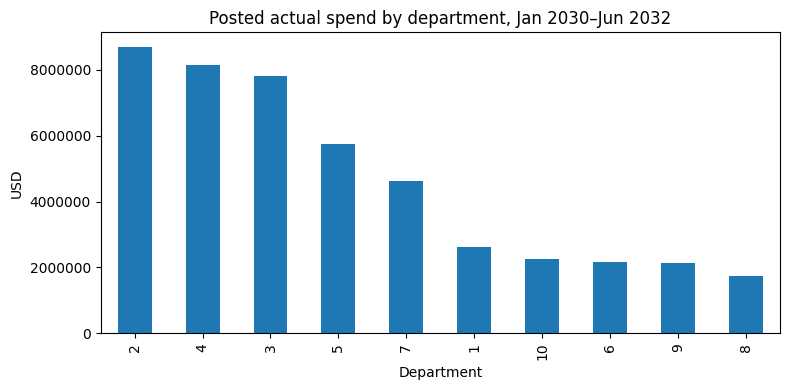

In [20]:
actual_rows["Year"] = actual_rows["Posting Period"].dt.year
actual_by_year = actual_rows.groupby("Year")["Amount (USD)"].sum().rename("Actual (USD)")
actual_by_class = actual_rows.groupby("Txn Class")["Amount (USD)"].sum().rename("Actual (USD)")
actual_by_dept = actual_rows.groupby("Dept")["Amount (USD)"].sum().rename("Actual (USD)")
for title, result in [("By year (2032: Jan–Jun only)", actual_by_year),
                      ("By cost class", actual_by_class), ("By department", actual_by_dept)]:
    print("\n" + title)
    display(result.to_frame())
    assert np.isclose(float(result.sum()), actual_spend, atol=0.01)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
actual_by_dept.sort_values(ascending=False).plot.bar(ax=ax)
ax.set_title("Posted actual spend by department, Jan 2030–Jun 2032")
ax.set_xlabel("Department")
ax.set_ylabel("USD")
ax.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

### 8.1 Monthly actuals versus time-phased baseline

Aggregate both datasets by posting month, using the same 30-month interval. The chart makes the trajectory visible and helps distinguish steadily elevated costs from concentrated months. The cumulative view is **not** a new forecast; it is a historic performance comparison.

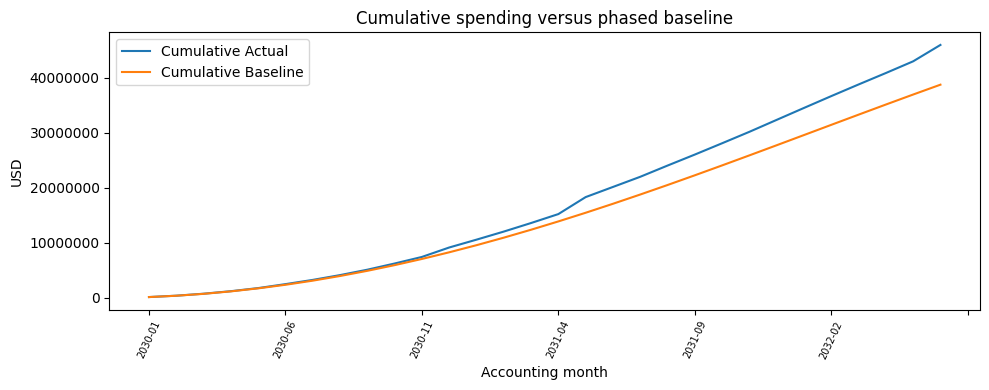

In [21]:
monthly_actual = actual_rows.groupby("Posting Period")["Amount (USD)"].sum()
monthly_baseline = BLP_long.loc[BLP_long["Posting Period"].le(AS_OF)].groupby("Posting Period")["Baseline (USD)"].sum()
monthly_comparison = pd.DataFrame({"Actual": monthly_actual, "Baseline": monthly_baseline}).fillna(0).sort_index()
monthly_comparison["Cumulative Actual"] = monthly_comparison["Actual"].cumsum()
monthly_comparison["Cumulative Baseline"] = monthly_comparison["Baseline"].cumsum()
assert np.isclose(monthly_comparison["Actual"].sum(), actual_spend, atol=0.01)
assert np.isclose(monthly_comparison["Baseline"].sum(), planned_to_date, atol=0.01)
fig, ax = plt.subplots(figsize=(10, 4))
monthly_comparison[["Cumulative Actual", "Cumulative Baseline"]].set_axis(
    monthly_comparison.index.astype(str)
).plot(ax=ax)
ax.set_title("Cumulative spending versus phased baseline")
ax.set_xlabel("Accounting month")
ax.set_ylabel("USD")
ax.tick_params(axis="x", rotation=65, labelsize=7)
ax.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

## 9. Questions 3–4 — Completion forecasts and the funding ceiling

**Scenario A — department-submitted forecast.** Use the current **June 2032** vintage *only* for July 2032–Dec 2033. Sum it with posted actuals; the December 2031 vintage covers Jan–Jun 2032 and is superseded by postings.

**Scenario B — recent spending relative to plan.** Calculate `Jan–Jun 2032 actual / Jan–Jun 2032 baseline`. Multiply the ratio by the remaining original phased baseline, then add actuals through June. This is a *sensitivity scenario*, not an independent statistical confidence interval. It assumes recent relative overrun persists throughout the remaining program.

For transparency, also calculate an **absolute** six-month burn-rate extrapolation, which is less credible if planned monthly outlays accelerate or decline. None of these forecasts incorporates a formally approved scope reduction.

In [22]:
future_current = GLE_df.loc[
    GLE_df["Rec Type"].eq("Forecast")
    & GLE_df["Version"].eq("Fcst Jun-32")
    & GLE_df["Posting Period"].gt(AS_OF)
].copy()
assert future_current["Posting Period"].nunique() == 18
assert future_current["Posting Period"].min() == pd.Period("2032-07", freq="M")
assert future_current["Posting Period"].max() == pd.Period("2033-12", freq="M")
submitted_future = float(future_current["Amount (USD)"].sum())
submitted_completion = actual_spend + submitted_future

recent_start = pd.Period("2032-01", freq="M")
recent_actual = float(actual_rows.loc[actual_rows["Posting Period"].ge(recent_start), "Amount (USD)"].sum())
recent_plan = float(BLP_long.loc[
    BLP_long["Posting Period"].between(recent_start, AS_OF), "Baseline (USD)"
].sum())
assert recent_plan > 0
recent_plan_ratio = recent_actual / recent_plan
phased_future = remaining_baseline * recent_plan_ratio
phased_completion = actual_spend + phased_future
flat_monthly_burn = recent_actual / 6
flat_completion = actual_spend + 18*flat_monthly_burn
scenario = pd.DataFrame({
    "Projection": ["Submitted Jun-2032 forecast", "Recent relative-to-plan (6m)", "Flat $/month burn (sensitivity)"],
    "Actual to date": [actual_spend]*3,
    "Future spend": [submitted_future, phased_future, 18*flat_monthly_burn],
    "Final cost": [submitted_completion, phased_completion, flat_completion]
}).set_index("Projection")
scenario["Funding gap (+shortfall)"] = scenario["Final cost"] - FUNDING_CEILING
scenario["Required future reduction %"] = scenario["Funding gap (+shortfall)"].clip(lower=0) / scenario["Future spend"]
display(scenario.round(2))
print(f"Recent six-month ratio to phased plan: {recent_plan_ratio:.2%}")
print(f"Six-month average monthly burn: ${flat_monthly_burn:,.2f}")
print(f"Department submission exceeds ceiling by: ${submitted_completion-FUNDING_CEILING:,.2f}")
print(f"Plan-phased continuation exceeds ceiling by: ${phased_completion-FUNDING_CEILING:,.2f}")

,Actual to date,Future spend,Final cost,Funding gap (+shortfall),Required future reduction %
Projection,,,,,
Submitted Jun-2032 forecast,45958579.78,19830668.26,65789248.04,5789248.04,0.29
Recent relative-to-plan (6m),45958579.78,23835281.52,69793861.30,9793861.30,0.41
Flat $/month burn (sensitivity),45958579.78,40859532.15,86818111.93,26818111.93,0.66


Recent six-month ratio to phased plan: 123.72%
Six-month average monthly burn: $2,269,974.01
Department submission exceeds ceiling by: $5,789,248.04
Plan-phased continuation exceeds ceiling by: $9,793,861.30


### 9.1 Why the scenarios differ

The department submission reflects stated future plans, but it could be optimistic if departments have historically exceeded their baseline. The plan-phased continuation is a useful *challenge case* because it carries forward the most recent overrun ratio and respects monthly phasing. The flat dollar-burn projection ignores future phasing and is therefore included only to show sensitivity. The recommended decision stance is to budget against the **higher-risk plan-phased continuation** while asking departments to reconcile and re-submit their remaining forecasts; its accuracy cannot be established from this single case dataset.

## 10. Question 5 — Department watchlist

Compare **actuals through June 2032** to the **corresponding phased baseline through June 2032** by department. Also compare **actual + current future forecast** to the **full original department baseline**. These are distinct signals: the first is observed overspend; the second is projected completion exposure. We also break the *historical* variance into Labor versus Non-Labor so leadership can identify the driver.

The watchlist is sorted by historical dollar overrun (not merely the largest department). It can be re-sorted by final-plan variance as a second prioritization view.

In [23]:
base_ytd = BLP_long.loc[BLP_long["Posting Period"].le(AS_OF)]
dept_watch = pd.DataFrame({
    "Actual to Jun-32": actual_rows.groupby("Dept")["Amount (USD)"].sum(),
    "Phased baseline to Jun-32": base_ytd.groupby("Dept")["Baseline (USD)"].sum(),
    "Current future forecast": future_current.groupby("Dept")["Amount (USD)"].sum(),
    "Full original baseline": BLP_long.groupby("Dept")["Baseline (USD)"].sum()
}).fillna(0)
dept_watch["YTD overrun (+)"] = dept_watch["Actual to Jun-32"] - dept_watch["Phased baseline to Jun-32"]
dept_watch["YTD overrun %"] = dept_watch["YTD overrun (+)"] / dept_watch["Phased baseline to Jun-32"]
dept_watch["Projected total"] = dept_watch["Actual to Jun-32"] + dept_watch["Current future forecast"]
dept_watch["Projected vs full baseline"] = dept_watch["Projected total"] - dept_watch["Full original baseline"]
dept_watch = dept_watch.sort_values("YTD overrun (+)", ascending=False)
display(dept_watch.round(2))
assert np.isclose(dept_watch["Actual to Jun-32"].sum(), actual_spend, atol=0.01)
assert np.isclose(dept_watch["Current future forecast"].sum(), submitted_future, atol=0.01)

actual_dept_class = actual_rows.groupby(["Dept", "Txn Class"])["Amount (USD)"].sum()
base_dept_class = base_ytd.groupby(["Dept", "Txn Class"])["Baseline (USD)"].sum()
drivers = pd.DataFrame({"Actual": actual_dept_class, "Baseline": base_dept_class}).fillna(0)
drivers["Overrun (+)"] = drivers["Actual"] - drivers["Baseline"]
print("Variance drivers by department and class:")
display(drivers.sort_values("Overrun (+)", ascending=False).round(2).head(15))

,Actual to Jun-32,Phased baseline to Jun-32,Current future forecast,Full original baseline,YTD overrun (+),YTD overrun %,Projected total,Projected vs full baseline
Dept,,,,,,,,
3,7830779.1,5983871.57,1560245.74,7500000.02,1846907.53,0.31,9391024.84,1891024.82
7,4619141.35,3220681.20,2863252.29,6000000.05,1398460.15,0.43,7482393.64,1482393.59
4,8143513.23,6953915.68,4172023.03,10999999.97,1189597.55,0.17,12315536.26,1315536.29
5,5762174.76,4586897.45,1948042.21,6500000.02,1175277.31,0.26,7710216.97,1210216.95
2,8708979.46,7636434.82,1337136.16,8999999.98,1072544.64,0.14,10046115.62,1046115.64
9,2146127.34,1561576.57,1998709.61,3500000.01,584550.77,0.37,4144836.95,644836.94
8,1748406.32,1643366.86,856594.52,2499999.96,105039.46,0.06,2605000.84,105000.88
1,2603565.04,2555278.97,1478228.06,3999999.98,48286.07,0.02,4081793.1,81793.12
10,2247158.58,2258450.88,1228062.92,3499999.98,-11292.3,-0.01,3475221.5,-24778.48


Variance drivers by department and class:


Actual    Baseline  Overrun (+)
Dept Txn Class                                     
3    Non-Labor  6271833.48  4487903.68    1783929.8
7    Labor      3359466.08  2093442.78    1266023.3
2    Labor      7234721.17  6109147.88   1125573.29
5    Labor      3438261.98  2752138.48     686123.5
4    Labor      4444587.78  3824653.59    619934.19
     Non-Labor  3698925.45  3129262.09    569663.36
5    Non-Labor  2323912.78  1834758.97    489153.81
9    Labor      1544355.26  1093103.60    451251.66
     Non-Labor   601772.08   468472.97    133299.11
7    Non-Labor  1259675.27  1127238.42    132436.85
8    Non-Labor   502580.95   410841.69     91739.26
3    Labor      1558945.62  1495967.89     62977.73
1    Labor      2209992.66  2171987.14     38005.52
8    Labor      1245825.37  1232525.17      13300.2
1    Non-Labor   393572.38   383291.83     10280.55

### 10.1 Practical watchlist decisions

The most serious *observed* overrun departments should be reviewed first. The department-level projected variance compares their submitted finish cost with the original baseline; **a projection above a department baseline is not itself a violation of the overall $60m ceiling**, because the management reserve exists at project level. However, widespread departmental overspend makes that reserve less able to absorb future surprises. Use the Labor/Non-Labor drivers to request specific cost-driver explanations and revised remaining monthly commitments.

## 11. Question 6 — Actions to close the funding gap

Start with the **minimum** required control target: reduce remaining submitted spend by `submitted completion − $60m`. A more conservative target uses the plan-phased continuation gap. The targets below are **illustrative allocation ceilings for discussion**, not identified savings opportunities or approved cost cuts: amounts should be verified against contracts, payroll commitments and critical-path work before implementation.

The worksheet allocates the *submitted-forecast gap* across departments in proportion to their **positive historically observed overspend**, subject to their remaining forecast spend. This makes the prioritization transparent and feasible in arithmetic terms, but the commercial feasibility still needs leadership review.

In [24]:
# Allocate illustrative target reductions toward the submitted-forecast funding gap.
required_submitted_reduction = max(0.0, submitted_completion - FUNDING_CEILING)
weights = dept_watch["YTD overrun (+)"].clip(lower=0).astype(float)
capacity = dept_watch["Current future forecast"].astype(float)
alloc = pd.Series(0.0, index=dept_watch.index)
remaining = required_submitted_reduction
for _ in range(len(alloc) + 2):
    eligible = (capacity - alloc > 1e-6) & (weights > 0)
    if remaining < 0.005 or not eligible.any():
        break
    incr = remaining * weights[eligible] / weights[eligible].sum()
    incr = np.minimum(incr, (capacity - alloc)[eligible])
    alloc.loc[eligible] += incr
    remaining = required_submitted_reduction - alloc.sum()
if remaining > 0.01:
    print("WARNING: watchlist allocation does not cover the entire gap; consider other departments")
recovery = pd.DataFrame({
    "Future forecast": capacity,
    "YTD observed overrun": dept_watch["YTD overrun (+)"],
    "Illustrative reduction target": alloc
}).sort_values("Illustrative reduction target", ascending=False)
recovery["Reduction / future forecast"] = recovery["Illustrative reduction target"] / recovery["Future forecast"]
display(recovery.round(2))
print(f"Submitted-case shortfall: ${required_submitted_reduction:,.2f}")
print(f"Illustrative reduction allocated: ${alloc.sum():,.2f}")
print(f"Unallocated portion: ${max(0, remaining):,.2f}")
print(f"Risk-case shortfall: ${max(0, phased_completion - FUNDING_CEILING):,.2f}")
print("Note: illustration is a negotiation target, not an evidenced cost saving.")

,Future forecast,YTD observed overrun,Illustrative reduction target,Reduction / future forecast
Dept,,,,
3,1560245.74,1846907.53,1440869.25,0.92
7,2863252.29,1398460.15,1091011.97,0.38
4,4172023.03,1189597.55,928067.32,0.22
5,1948042.21,1175277.31,916895.35,0.47
2,1337136.16,1072544.64,836748.22,0.63
9,1998709.61,584550.77,456038.66,0.23
8,856594.52,105039.46,81946.78,0.10
1,1478228.06,48286.07,37670.49,0.03
10,1228062.92,-11292.3,0.00,0.00


Submitted-case shortfall: $5,789,248.04
Illustrative reduction allocated: $5,789,248.04
Unallocated portion: $0.00
Risk-case shortfall: $9,793,861.30
Note: illustration is a negotiation target, not an evidenced cost saving.


## 12. Management readout — six questions answered

The following cell generates an up-to-date text summary from the validated calculations (no separately typed amounts). It answers the six required questions in the brief's order. Treat the June forecast as the **submitted** outlook and the phased recent-spend projection as a more conservative **challenge case**. Neither forecast is guaranteed, and the unresolved printed-total discrepancies should be mentioned in the readout and appendix.

In [25]:
top3 = dept_watch.head(3)
print("PROJECT X — LEADERSHIP READOUT (as of June 2032)")
print(f"1. Spent ${actual_spend/1e6:.2f}m ({actual_spend/FUNDING_CEILING:.1%} of $60m); "
      f"phased baseline to date ${planned_to_date/1e6:.2f}m; overrun ${ (actual_spend-planned_to_date)/1e6:.2f}m.")
print(f"2. Posted actuals: 2030 ${actual_by_year[2030]/1e6:.2f}m; 2031 ${actual_by_year[2031]/1e6:.2f}m; "
      f"Jan–Jun 2032 ${actual_by_year[2032]/1e6:.2f}m. Labor ${actual_by_class['Labor']/1e6:.2f}m; "
      f"Non-Labor ${actual_by_class['Non-Labor']/1e6:.2f}m.")
print(f"3. Funding available today ${remaining_funding/1e6:.2f}m. Jun-32 department forecast future "
      f"${submitted_future/1e6:.2f}m; six-month relative-to-plan future ${phased_future/1e6:.2f}m.")
print(f"4. Completion: submitted ${submitted_completion/1e6:.2f}m "
      f"(shortfall ${(submitted_completion-FUNDING_CEILING)/1e6:.2f}m); "
      f"phased trend ${phased_completion/1e6:.2f}m "
      f"(shortfall ${(phased_completion-FUNDING_CEILING)/1e6:.2f}m). "
      "Prefer phased trend as risk case, pending forecast refresh.")
print("5. Top historical department overruns:", "; ".join(
    f"Dept {int(i)} ${row['YTD overrun (+)']/1e6:.2f}m" for i,row in top3.iterrows()))
print(f"6. Seek at least ${(submitted_completion-FUNDING_CEILING)/1e6:.2f}m verified future reductions "
      f"to meet ceiling under submission, with a contingency response for risk-case ${ (phased_completion-FUNDING_CEILING)/1e6:.2f}m gap; "
      "freeze nonessential spend, rephase work, validate commitments, secure sponsor decisions.")

PROJECT X — LEADERSHIP READOUT (as of June 2032)
1. Spent $45.96m (76.6% of $60m); phased baseline to date $38.73m; overrun $7.22m.
2. Posted actuals: 2030 $9.14m; 2031 $23.20m; Jan–Jun 2032 $13.62m. Labor $27.44m; Non-Labor $18.52m.
3. Funding available today $14.04m. Jun-32 department forecast future $19.83m; six-month relative-to-plan future $23.84m.
4. Completion: submitted $65.79m (shortfall $5.79m); phased trend $69.79m (shortfall $9.79m). Prefer phased trend as risk case, pending forecast refresh.
5. Top historical department overruns: Dept 3 $1.85m; Dept 7 $1.40m; Dept 4 $1.19m
6. Seek at least $5.79m verified future reductions to meet ceiling under submission, with a contingency response for risk-case $9.79m gap; freeze nonessential spend, rephase work, validate commitments, secure sponsor decisions.


## 13. Limitations, reconciliation exceptions and submission requirements

**Unresolved source controls.** After removing 18 exact extra copies ($159,832.69), the printed FY2030 subtotal, FY2031 subtotal, and source grand total **still differ** from the correctly aggregated transaction rows. Those control totals are not overwritten or treated as a financial definition. The raw-to-clean bridge itself reconciles; the external printed totals do not. Include both figures and variance in the appendix.

**Forecast limitations.** The June 2032 forecast is department-submitted, not an audited commitment schedule. The six-month relative-to-plan projection assumes the recent overrun persists and is sensitive to the unusually high June 2032 actual spend. It is prudent as a challenge scenario, not provably the most accurate estimate. The flat burn sensitivity is intentionally less planning-aware.

**Recommendations depend on feasibility.** The allocation table is an indicative dollar target; it is not evidence that specific contracts, headcount or purchase orders can be reduced by that amount. Request confirmed, costed actions from department owners, verify vendor and workforce commitments, and escalate any residual funding shortfall. The $2m reserve is already included in the $60m ceiling and must not be added again.

**Required final deliverables (per case brief).** (1) One-page executive summary with decisive recommendations, (2) analysis workbook with traceable formulas/charts, (3) cleaning assumptions and reconciliations appendix; prepare a 10-minute readout plus 5-minute Q&A. This notebook supplies transparent computational workings but is **not itself a live-formula Excel analysis workbook**.

## Appendix A — Cleaning and modeling decision log

| Item | Finding | Treatment / effect |
|---|---|---|
| Header and report rows | Four header rows; 2 annual subtotal rows; 1 grand total | Import correct header; preserve printed controls outside transaction totals |
| Posting Period | Mixed month strings/dates; 48 monthly periods | Normalize to `period[M]` |
| Rec Type and Version | Abbreviations; 10 missing record types | Normalize and infer missing types from verified posted/forecast versions |
| Dept / Cost Center | Inconsistent labels; 14 missing departments | Extract identifier, validate against cost center, recover missing values |
| Txn Class | Label variants; 25 contract-labor misclassifications | Apply official GL-account policy; preserve original labels and conflicts |
| GL Acct and Description | Floats and 36 description variants | Integer account codes; standard description map |
| Amounts | Mixed numeric/strings, currency formatting | Parse without dropping signs; preserve original values |
| Reversals | 10 negative reversal records | Keep signed pairs, check linked original documents |
| Duplicates | 18 extra exact source records | Preserve audit copy and exclude $159,832.69 once |
| Historic as-of scope | Actuals through 2032-06 | Exclude historic forecast vintages from actual spend |
| Future forecast | `Fcst Jun-32`, Jul 2032–Dec 2033 | Use it as submitted future view only |
| Alternative projection | Recent six months above phased plan | Apply recent actual/plan factor to remaining phased baseline |
| Source control totals | 2030/2031 and printed grand total inconsistent | Keep quantified differences, do not invent a balancing adjustment |
| Plan total | $57,999,999.99 due to precision | Accept 1-cent rounding relative to $58m official baseline |
| Recommendations | Funding gap under both scenarios | Dollar-sized targets are illustrative and subject to feasibility verification |

## Appendix B — Quality assurance checklist

- [x] Transaction-level pipeline can be run from a fresh kernel.
- [x] Explicit raw-to-clean financial bridge and documented duplicate exclusions.
- [x] Existing source-total discrepancies remain visible.
- [x] Approved monthly baseline reconciled to within 1 cent of $58 million.
- [x] Baseline reshaped to 960 unique department/class/month records.
- [x] Actuals and distinct forecast vintages separated by as-of date.
- [x] Reported spend by year, category and department reconciles to actuals.
- [x] Submitted and plan-phased future projection scenarios and their ceiling gaps calculated.
- [x] Department watchlist and labor/non-labor variance drivers calculated.
- [x] Funding-reduction targets quantified as illustrative, not committed savings.
- [ ] Create a reviewer-friendly Excel workbook with linked formulas and charts.
- [ ] Format a one-page executive summary and an executive readout.
- [ ] Obtain independent reconciliation or authoritative explanation of inconsistent printed source controls.